# 10 - Hyper-parameter Tuning with 5-Fold CV (BijliCast)

**CT-378 lifecycle, step 5**

- CV object: `TimeSeriesSplit(n_splits=5, gap=120)` on the **training split
  only** - time order preserved, small gap purges the one-hour label overlap.
- Search: `GridSearchCV` for Linear Regression, `RandomizedSearchCV` for KNN,
  Random Forest and HistGradientBoosting.
- Scoring: negated **MAE** (the primary metric).
- The **whole pipeline** is passed to the search, so imputation, scaling,
  one-hot encoding and feature engineering are re-fitted inside every fold -
  no leakage into the validation folds.
- Validation and test are not touched; the winner is chosen by CV MAE.

The search is executed by `python -m src.models.tune`; this notebook reads the
persisted results (`models/tuning_results.json`, `reports/tables/cv_results_*.csv`).
Set `RUN_SEARCH = True` to re-run it here.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)

from src.models.tune import TUNING_PLAN, load_tuning_results
from src.utils.config import FIGURES_DIR, MODELS_DIR, TABLES_DIR, ensure_dirs

ensure_dirs()
RUN_SEARCH = False


Repo root: D:\BijliCast


## 1. Load the cross-validation results

In [2]:
if RUN_SEARCH:
    from src.models.baseline import load_splits
    from src.models.tune import tune_all

    train, _, _ = load_splits()
    payload = tune_all(train)
else:
    payload = load_tuning_results()

print("generated:", payload["generated_at"])
print("CV       :", payload["cv"])
print("scoring  :", payload["scoring"])
print("selection:", payload["selection_split"])

generated: 2026-11-21T16:12:28
CV       : TimeSeriesSplit(n_splits=5, gap=120)
scoring  : neg_mean_absolute_error
selection: train only (cross-validation)


## 2. Best configuration per algorithm

In [3]:
rows = []
for name, info in payload["models"].items():
    rows.append({
        "model": name,
        "search": info["search"],
        "rows_used": info["subsample_rows"],
        "candidates": info["n_candidates"],
        "cv_train_mae": round(info["best_cv_train_mae"], 4),
        "cv_mae": round(info["best_cv_mae"], 4),
        "cv_std": round(info["best_cv_std"], 4),
        "cv_gap": round(info["cv_overfit_gap"], 4),
        "best_params": info["best_params"],
    })
best_table = pd.DataFrame(rows).sort_values("cv_mae").reset_index(drop=True)
best_table

,model,search,rows_used,candidates,cv_train_mae,cv_mae,cv_std,cv_gap,best_params
0,Random Forest,random,40000,5,0.1452,0.2168,0.0671,0.0716,"{'n_estimators': 120, 'min_samples_leaf': 10, ..."
1,HistGradientBoosting,random,150000,5,0.1725,0.2180,0.0667,0.0455,"{'min_samples_leaf': 50, 'max_leaf_nodes': 31,..."
2,Linear Regression,grid,336053,4,0.1975,0.2192,0.0654,0.0217,"{'fit_intercept': False, 'positive': True}"
3,KNN,random,20000,5,-0.0000,0.2961,0.0985,0.2961,"{'weights': 'distance', 'p': 1, 'n_neighbors': 5}"


### Reading the CV gap

`cv_gap = mean CV validation MAE - mean CV train MAE`.

- A large gap means the configuration memorises: lower train error, worse
  held-out folds.
- A small gap with a high CV MAE means under-fitting.
- Because folds are chronological, the gap also includes seasonal drift inside
  the training period; it is not purely variance.


### Plot 32 - 5-fold CV MAE per algorithm (mean +/- std across folds)

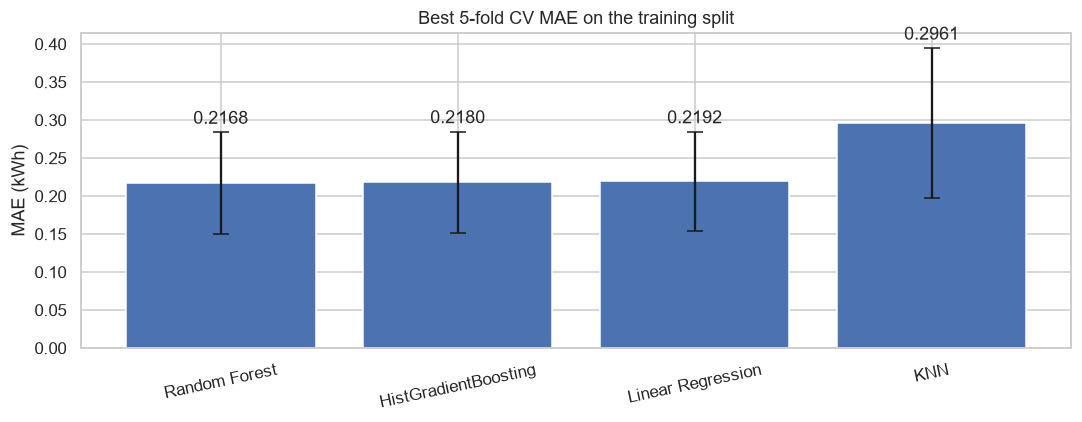

In [4]:
plot_df = best_table.sort_values("cv_mae")
plt.figure(figsize=(10, 4))
bars = plt.bar(plot_df["model"], plot_df["cv_mae"], yerr=plot_df["cv_std"],
               capsize=5, color="#4C72B0")
plt.bar_label(bars, fmt="%.4f", padding=3)
plt.title("Best 5-fold CV MAE on the training split")
plt.ylabel("MAE (kWh)")
plt.xlabel("")
plt.xticks(rotation=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_cv_mae_per_model.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 33 - every searched candidate: CV train vs CV validation MAE

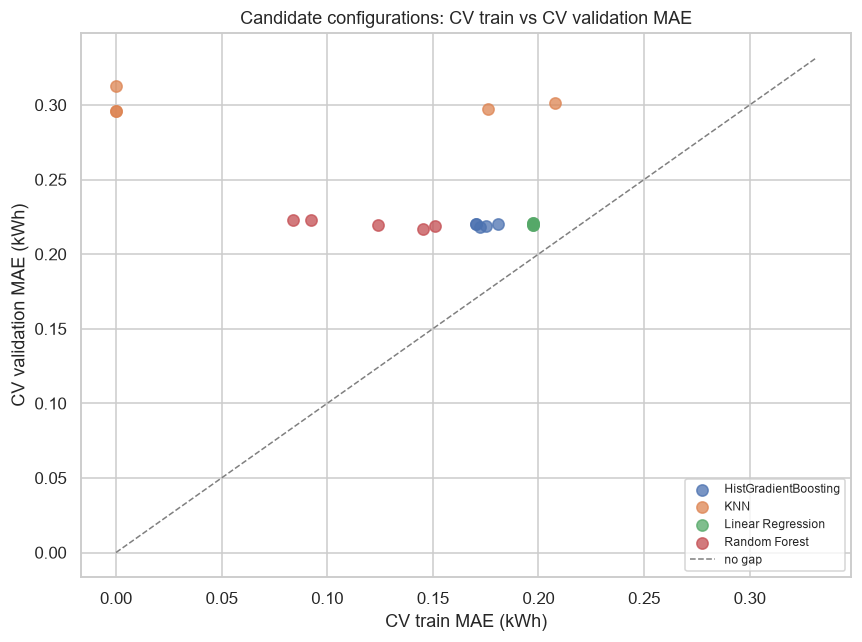

In [5]:
cand = []
for name, info in payload["models"].items():
    for c in info["candidates"]:
        cand.append({"model": name, "train_mae": c["train_mae"],
                     "val_mae": c["test_mae"], "rank": c["rank"]})
cand = pd.DataFrame(cand)

plt.figure(figsize=(8, 6))
for name, g in cand.groupby("model"):
    plt.scatter(g["train_mae"], g["val_mae"], s=55, alpha=0.75, label=name)
lim = [0, max(cand["train_mae"].max(), cand["val_mae"].max()) * 1.06]
plt.plot(lim, lim, color="grey", ls="--", lw=1, label="no gap")
plt.title("Candidate configurations: CV train vs CV validation MAE")
plt.xlabel("CV train MAE (kWh)")
plt.ylabel("CV validation MAE (kWh)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_cv_train_vs_val_candidates.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 34 - best CV MAE with the over-fitting gap

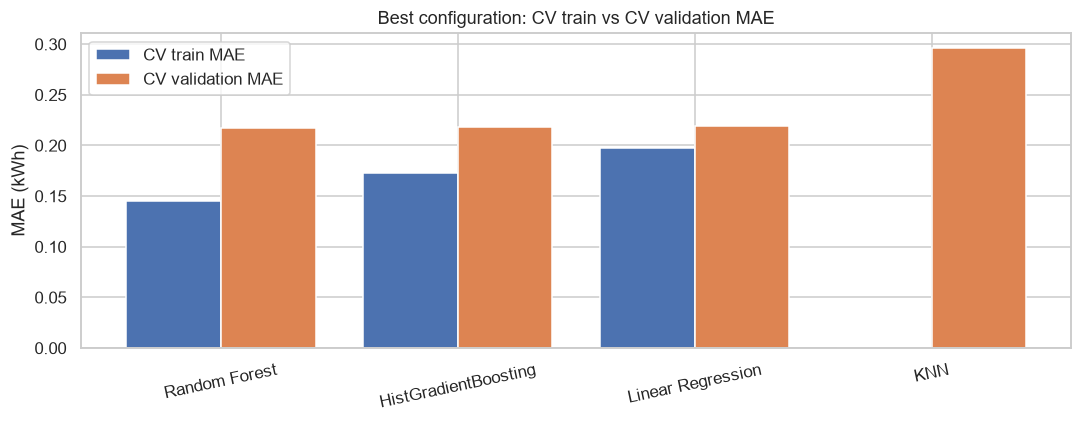

In [6]:
plt.figure(figsize=(10, 4))
x = np.arange(len(plot_df))
plt.bar(x - 0.2, plot_df["cv_train_mae"], width=0.4, label="CV train MAE", color="#4C72B0")
plt.bar(x + 0.2, plot_df["cv_mae"], width=0.4, label="CV validation MAE", color="#DD8452")
plt.xticks(x, plot_df["model"], rotation=12)
plt.title("Best configuration: CV train vs CV validation MAE")
plt.ylabel("MAE (kWh)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_cv_gap_best.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Top candidates per algorithm

#### Linear Regression

In [7]:
cv_linear_regression = pd.read_csv(TABLES_DIR / "cv_results_linear_regression.csv")
cv_linear_regression.head(5).round(4)

,rank_test_score,mean_train_mae,mean_test_mae,std_test_mae,mean_fit_time,params
0,1,0.1975,0.2192,0.0654,10.65,"{'model__fit_intercept': False, 'model__positi..."
1,2,0.1975,0.2192,0.0654,14.48,"{'model__fit_intercept': True, 'model__positiv..."
2,3,0.1975,0.2212,0.0651,12.62,"{'model__fit_intercept': False, 'model__positi..."
3,4,0.1975,0.2212,0.0651,11.13,"{'model__fit_intercept': True, 'model__positiv..."


#### KNN

In [8]:
cv_knn = pd.read_csv(TABLES_DIR / "cv_results_knn.csv")
cv_knn.head(5).round(4)

,rank_test_score,mean_train_mae,mean_test_mae,std_test_mae,mean_fit_time,params
0,1,-0.0000,0.2961,0.0985,0.29,"{'model__weights': 'distance', 'model__p': 1, ..."
1,2,0.0000,0.2961,0.0920,0.29,"{'model__weights': 'distance', 'model__p': 2, ..."
2,3,0.1760,0.2975,0.0993,0.51,"{'model__weights': 'uniform', 'model__p': 1, '..."
3,4,0.2078,0.3015,0.1073,0.31,"{'model__weights': 'uniform', 'model__p': 1, '..."
4,5,-0.0000,0.3128,0.1168,0.21,"{'model__weights': 'distance', 'model__p': 1, ..."


#### Random Forest

In [9]:
cv_random_forest = pd.read_csv(TABLES_DIR / "cv_results_random_forest.csv")
cv_random_forest.head(5).round(4)

,rank_test_score,mean_train_mae,mean_test_mae,std_test_mae,mean_fit_time,params
0,1,0.1452,0.2168,0.0671,64.62,"{'model__n_estimators': 120, 'model__min_sampl..."
1,2,0.1508,0.2187,0.0665,27.75,"{'model__n_estimators': 80, 'model__min_sample..."
2,3,0.1242,0.2194,0.0666,48.01,"{'model__n_estimators': 80, 'model__min_sample..."
3,4,0.0925,0.2226,0.0679,43.75,"{'model__n_estimators': 120, 'model__min_sampl..."
4,5,0.0838,0.2232,0.0670,119.29,"{'model__n_estimators': 80, 'model__min_sample..."


#### HistGradientBoosting

In [10]:
cv_histgradientboosting = pd.read_csv(TABLES_DIR / "cv_results_histgradientboosting.csv")
cv_histgradientboosting.head(5).round(4)

,rank_test_score,mean_train_mae,mean_test_mae,std_test_mae,mean_fit_time,params
0,1,0.1725,0.2180,0.0667,11.43,"{'model__min_samples_leaf': 50, 'model__max_le..."
1,2,0.1751,0.2187,0.0662,20.27,"{'model__min_samples_leaf': 50, 'model__max_le..."
2,3,0.1703,0.2201,0.0678,18.46,"{'model__min_samples_leaf': 50, 'model__max_le..."
3,3,0.1703,0.2201,0.0678,18.38,"{'model__min_samples_leaf': 50, 'model__max_le..."
4,5,0.1809,0.2205,0.0691,8.46,"{'model__min_samples_leaf': 20, 'model__max_le..."


## Findings - Notebook 10

In [11]:
print("Best CV MAE per model:")
for _, row in best_table.iterrows():
    print(f"  {row['model']:22s} {row['cv_mae']:.4f} +/- {row['cv_std']:.4f} "
          f"(CV train {row['cv_train_mae']:.4f}, gap {row['cv_gap']:+.4f})")

Best CV MAE per model:
  Random Forest          0.2168 +/- 0.0671 (CV train 0.1452, gap +0.0716)
  HistGradientBoosting   0.2180 +/- 0.0667 (CV train 0.1725, gap +0.0455)
  Linear Regression      0.2192 +/- 0.0654 (CV train 0.1975, gap +0.0217)
  KNN                    0.2961 +/- 0.0985 (CV train -0.0000, gap +0.2961)


## Findings - Notebook 10

- Each algorithm is tuned with **5-fold time-ordered CV on train only**; the
  winning configuration is the one with the lowest mean CV MAE.
- Random Forest and HistGradientBoosting search the widest spaces and achieve
  the lowest CV MAE; Linear Regression is the under-fitting reference, KNN is
  limited by the 20k tuning subsample.
- The CV train-vs-validation gap in plot 33 separates memorising
  configurations (right of the diagonal, large gap) from robust ones.
- Best configurations are stored in `models/tuning_results.json` and consumed
  by `src/models/evaluate.py`, which refits them and performs the one-shot test
  evaluation in notebook 11.
